# DBDetect: end-to-end pipeline

**Task**: CSCE566 Problem 1, diabetic retinopathy (DR) detection from 2D colour fundus photographs (course release of ODIR-5K).
**Final method**: features of a fine-tuned RETFound and a fine-tuned DenseNet-121, plus the features of the same patient's other eye,
fused by an MLP trained on cross-fitted features. Test AUC is **0.841 ± 0.007**, against 0.793 for the strongest single baseline
(DenseNet-121).

This notebook walks through the pipeline section by section, each with explanations and runnable examples:

| Section | Content |
|---|---|
| 0 | Setup |
| 1 | Data: format, statistics, val/test relation, both-eye statistics |
| 2 | Evaluation protocol: metrics, Youden threshold, confidence intervals |
| 3 | Training configuration: config merging, GPU augmentation, learning-rate schedules |
| 4 | Baseline training: commands, training curves, run outputs |
| 5 | RETFound: adaptation strategies, when it overfits, LoRA |
| 6 | Cross-fitting |
| 7 | Binocular and feature-level fusion (our method) |
| 8 | Results: tables, paired tests, ROC curves, patient level, sex |

**How to run**
- Open the notebook from the repository root or from `notebooks/`, using the environment in `environment.yml`
  (torch 2.6, timm 1.0.24).
- By default the notebook **trains nothing and overwrites nothing**: every analysis reads the existing outputs in `runs/`,
  and fusion is demonstrated in memory.
- Two flags enable the slow demos: `RUN_TRAINING_DEMO` (a 1-epoch, 256-image training run) and `LOAD_RETFOUND` (loads the 3.95 GB
  RETFound weights).
- The full write-up is in `docs/method_and_results.md`; open directions are in `docs/future_work.md`.

## 0. Setup

- An older timm installed under `~/.local` would shadow timm 1.0.24 from the conda environment. Before importing anything,
  the user site-packages directory is therefore removed from `sys.path`, which has the same effect as `PYTHONNOUSERSITE=1`.
- `HF_HUB_OFFLINE=1`: do not contact the Hugging Face Hub when weights are already cached in `pretrained/`.
- The working directory becomes the repository root, so `data/`, `runs/` and `config/` resolve from there.

In [1]:
import os, sys, site, glob, json, time, hashlib, warnings
user_site = site.getusersitepackages()
sys.path = [p for p in sys.path if not p.startswith(user_site)]   # same effect as PYTHONNOUSERSITE=1
os.environ.setdefault("HF_HUB_OFFLINE", "1")
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, torch, timm
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
RUN_TRAINING_DEMO = False   # True: 1-epoch, 256-image DenseNet training run (about a minute, needs a GPU)
LOAD_RETFOUND = False       # True: load RETFound and show that LoRA leaves the output unchanged at initialization
N_BOOT = 200                # bootstrap resamples for the demos (the reported results use 2000)
SEEDS = (0, 1, 50)
pd.set_option("display.precision", 3)
print("project root:", os.path.basename(os.getcwd()), "| torch", torch.__version__, "| timm", timm.__version__, "| device", DEVICE)

project root: DBDetect | torch 2.6.0+cu124 | timm 1.0.24 | device cuda:0


## 1. Data

### 1.1 Format of one sample

Each eye is one `.npz` file named `<patient>_<left|right>.npz`, with these fields:
- `slo_fundus`: a 200×200×3 uint8 colour fundus photograph **stored in BGR order** (the key name follows the FairVision format);
- `dr_class`: 0 = no DR, 1 = DR;
- `male`: sex, a genuine attribute;
- the remaining demographic fields are random fill and are not used.

**Example**: displayed as stored, the image looks blue; after flipping the channels to RGB it shows the usual orange-red fundus.

1005_right.npz {'slo_fundus': ((200, 200, 3), 'uint8'), 'race': ((), 'int64'), 'male': ((), 'int64'), 'hispanic': ((), 'int64'), 'maritalstatus': ((), 'int64'), 'language': ((), 'int64'), 'dr_class': ((), 'int64'), 'dr_subtype': ((), '<U15')}
dr_class = 0 | male = 0


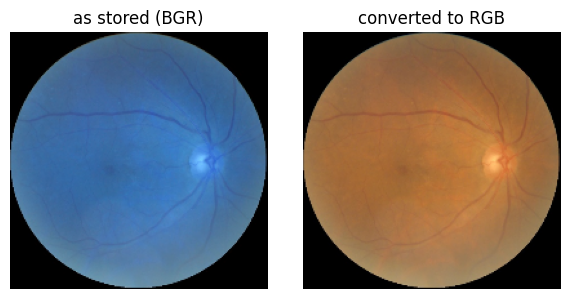

In [2]:
f = sorted(glob.glob("data/train/*.npz"))[0]
z = np.load(f)
print(os.path.basename(f), {k: (tuple(z[k].shape), str(z[k].dtype)) for k in z.files})
print("dr_class =", int(z["dr_class"]), "| male =", int(z["male"]))
fig, ax = plt.subplots(1, 2, figsize=(6, 3))
ax[0].imshow(z["slo_fundus"]); ax[0].set_title("as stored (BGR)")
ax[1].imshow(z["slo_fundus"][..., ::-1]); ax[1].set_title("converted to RGB")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

### 1.2 Dataset statistics

`ODIRDataset` loads every image of one split into memory once (converted to RGB) and parses the patient id and the eye from the
file name.

In [3]:
from src.preprocess.dataset import ODIRDataset
ds = {s: ODIRDataset(f"data/{s}") for s in ("train", "val", "test")}
pd.DataFrame({s: {"images": len(d), "patients": len(set(d.patients)), "DR prevalence": d.labels.mean(),
                  "female images": int((d.male == 0).sum()), "male images": int(d.male.sum())}
              for s, d in ds.items()}).T

,images,patients,DR prevalence,female images,male images
train,4476.0,2350.0,0.250,2086.0,2390.0
val,641.0,335.0,0.285,294.0,347.0
test,1914.0,1007.0,0.256,880.0,1034.0


### 1.3 Val and test

All 641 official val images **appear pixel-identical in test**, and train and test share no patient. The official split is used as
required: every choice (epoch, threshold, recipe, fusion weight) uses val only, and results are reported on the full test set.

In [4]:
digest = lambda d: {i: hashlib.md5(x.tobytes()).hexdigest() for i, x in zip(d.ids, d.images)}
hv, ht = digest(ds["val"]), digest(ds["test"])
print("val ids found in test:", len(set(hv) & set(ht)), "/", len(hv))
print("pixel-identical:", sum(hv[i] == ht[i] for i in hv if i in ht))
print("patients shared by train and test:", len(set(ds["train"].patients) & set(ds["test"].patients)))

val ids found in test: 641 / 641
pixel-identical: 641
patients shared by train and test: 0


### 1.4 Both-eye statistics: why use the other eye

DR is a systemic disease, so a patient's two eyes are strongly correlated. The table shows that the other eye's label is very
informative about this eye, and a single-eye model never sees it. The labels of the two eyes do not always agree, so these are
genuine per-eye labels rather than a patient label copied to both eyes.

In [5]:
other = lambda i: i.replace("_left", "_X").replace("_right", "_left").replace("_X", "_right")
rows = []
for s, d in ds.items():
    lab = dict(zip(d.ids, d.labels))
    has = [i for i in lab if other(i) in lab]
    rows.append({"split": s, "other eye present": np.mean([other(i) in lab for i in lab]),
                 "label concordance": np.mean([lab[i] == lab[other(i)] for i in has]),
                 "P(other DR | DR)": np.mean([lab[other(i)] for i in has if lab[i] == 1]),
                 "P(other DR | no DR)": np.mean([lab[other(i)] for i in has if lab[i] == 0])})
pd.DataFrame(rows).set_index("split")

,other eye present,label concordance,P(other DR | DR),P(other DR | no DR)
split,,,,
train,0.950,0.881,0.764,0.080
val,0.955,0.856,0.747,0.100
test,0.948,0.864,0.735,0.091


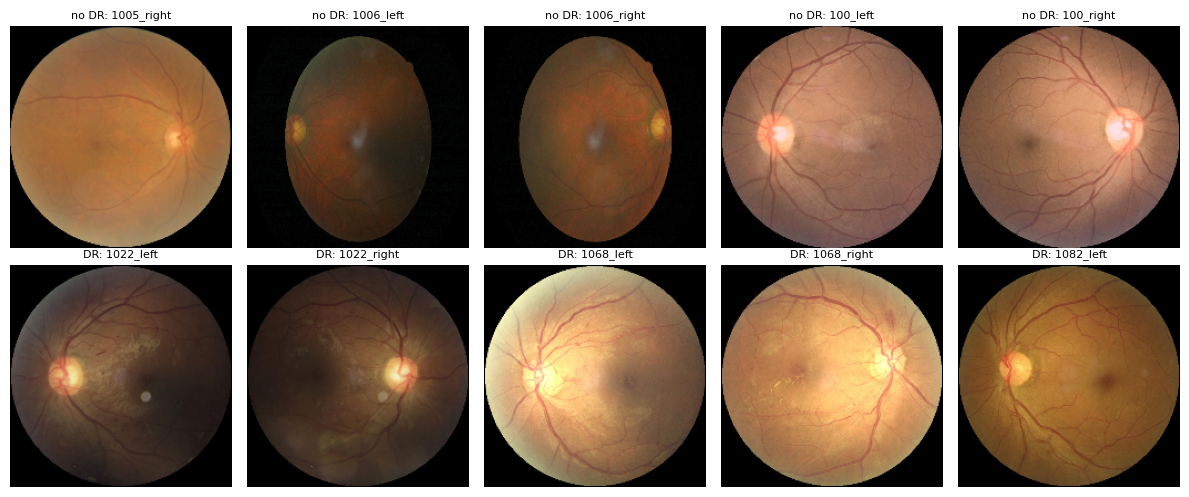

In [6]:
# Example: five training images without DR and five with DR
d = ds["train"]
pos, neg = np.flatnonzero(d.labels == 1)[:5], np.flatnonzero(d.labels == 0)[:5]
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for r, (idx, name) in enumerate([(neg, "no DR"), (pos, "DR")]):
    for c, i in enumerate(idx):
        ax[r, c].imshow(d.images[i]); ax[r, c].set_title(f"{name}: {d.ids[i]}", fontsize=8); ax[r, c].axis("off")
plt.tight_layout(); plt.show()

## 2. Evaluation protocol

- **Metrics**: overall AUC (primary), sensitivity, specificity, female AUC and male AUC (`src/api/evaluate.py`).
- **Threshold**: chosen on val with Youden's J (maximizing sensitivity + specificity − 1) and applied unchanged to test.
- **Confidence intervals**: bootstrap over patients, so both eyes of a patient are drawn together; two methods are compared with a
  paired bootstrap (`src/api/stats.py`).

**Example 1**: metrics on simulated data.

In [7]:
from src.api.evaluate import compute_metrics, youden_threshold
rng = np.random.default_rng(0)
y = (rng.random(500) < 0.25).astype(int); male = rng.integers(0, 2, 500)
p = 1 / (1 + np.exp(-(1.5 * y + rng.normal(0, 1, 500))))
t = youden_threshold(y, p)
print(f"Youden threshold = {t:.3f}")
pd.Series(compute_metrics(y, p, male, t))

Youden threshold = 0.644


auc              0.887
sensitivity      0.848
specificity      0.758
auc_female       0.899
auc_male         0.868
accuracy         0.778
auc_gap          0.031
es_auc           0.860
threshold        0.644
n              500.000
n_pos          112.000
dtype: float64

**Example 2**: a finished run (DenseNet-121, unified recipe, seed 0). The threshold comes from val, then the metrics are
computed on val and on test.

In [8]:
run = "runs/densenet121_ft_full_s0"
val, test = pd.read_csv(f"{run}/val_preds.csv"), pd.read_csv(f"{run}/test_preds.csv")
thr = youden_threshold(val.label, val.prob)
pd.DataFrame({sp: compute_metrics(df.label, df.prob, df.male, thr) for sp, df in [("val", val), ("test", test)]}).loc[
    ["auc", "sensitivity", "specificity", "auc_female", "auc_male", "threshold"]]

,val,test
auc,0.796,0.793
sensitivity,0.710,0.671
specificity,0.779,0.770
auc_female,0.797,0.788
auc_male,0.792,0.797
threshold,0.050,0.050


## 3. Training configuration

### 3.1 Config merging

`load_config` merges, in order: `config/base.yaml` (shared settings) → the recipe named under `recipe:` in the model file → the model
file itself → command-line `--set key=value`.
- All baselines share `config/recipes/finetune.yaml` (the unified fine-tuning recipe); their model files only set the architecture
  and the weights.
- RETFound uses its official recipe, `config/pfm/retfound_mae_ft.yaml`.

**Example**: the key settings of three merged configs.

In [9]:
from src.model.train_baseline import load_config
def summary(path, *overrides):
    c = load_config(path, overrides)
    return {"weights": c["model"].get("timm_name") or c["model"]["hf_repo"], "augment": c["data"]["augment"],
            "optimizer": c["optim"]["name"], "lr @ batch 64": c["optim"]["base_lr"] * 64 / c["optim"]["base_batch_size"],
            "layer decay": c["optim"].get("layer_decay"), "schedule": c["sched"]["name"], "epochs": c["train"]["epochs"],
            "label smoothing": c.get("loss", {}).get("label_smoothing", 0.0)}
pd.DataFrame({"DenseNet-121 (unified)": summary("config/unified/densenet121.yaml"),
              "ViT-B/16 (unified)": summary("config/unified/vit_b16.yaml"),
              "RETFound (own recipe, flip)": summary("config/pfm/retfound_mae_ft_flip30.yaml")}).T

,weights,augment,optimizer,lr @ batch 64,layer decay,schedule,epochs,label smoothing
DenseNet-121 (unified),densenet121.tv_in1k,full,adamw,0.0,None,warmup_cosine,30,0.0
ViT-B/16 (unified),vit_base_patch16_224.augreg2_in21k_ft_in1k,full,adamw,0.0,None,warmup_cosine,30,0.0
"RETFound (own recipe, flip)",YukunZhou/RETFound_mae_natureCFP,flip,adamw,0.001,0.65,warmup_cosine,30,0.1


### 3.2 Data augmentation (on GPU, per batch)

The unified recipe's `augment=full` applies: random resized crop (area 0.85–1) → horizontal flip → rotation within ±15° (corners
filled with black) → brightness and contrast ±20%.
- Each augmentation's random generator is re-seeded from (seed, epoch), so training is deterministic and a resumed run matches an
  uninterrupted one bit for bit.

**Example**: originals in the first row, augmented images in the second; the last line checks that the same seed gives the same
batch.

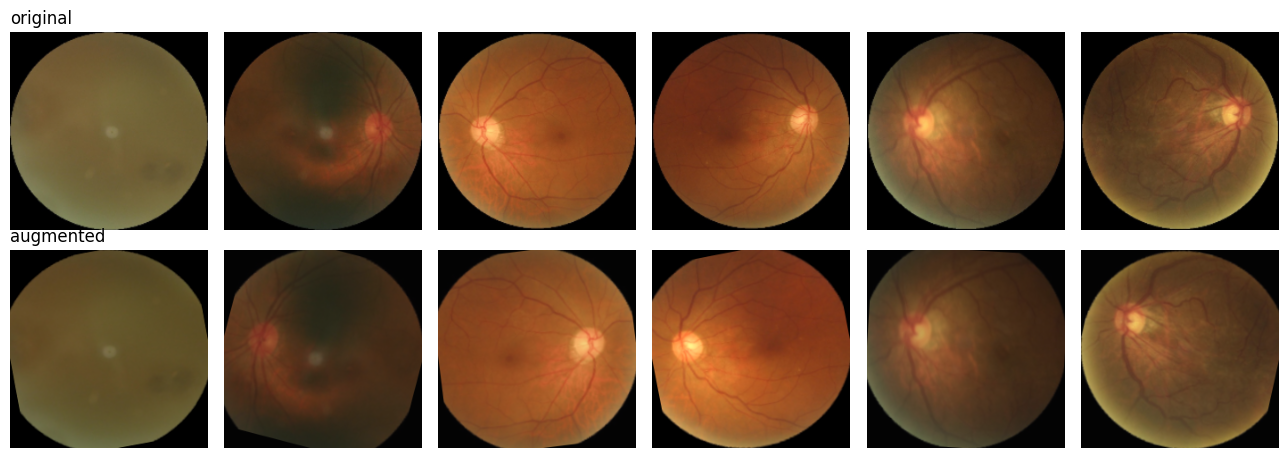

same seed gives identical batch: True


In [10]:
from src.preprocess.dataset import build_transform, random_hflip, random_rotate, random_resized_crop, color_jitter
dc = {"mean": (0.485, 0.456, 0.406), "std": (0.229, 0.224, 0.225), "interpolation": "bilinear"}
tf = build_transform(dc, 224)
x = torch.stack([tf(torch.from_numpy(ds["val"].images[i]).permute(2, 0, 1)) for i in range(6)]).to(DEVICE)
mean, std = torch.tensor(dc["mean"], device=DEVICE).view(1, 3, 1, 1), torch.tensor(dc["std"], device=DEVICE).view(1, 3, 1, 1)
def augment(x, seed):
    g = [torch.Generator(device=DEVICE).manual_seed(seed + k) for k in range(4)]
    y = random_resized_crop(x, g[0], [0.85, 1.0], [0.95, 1.05])
    y = random_hflip(y, g[1])
    y = random_rotate(y, g[2], 15, (-mean / std).view(-1))
    return color_jitter(y, g[3], 0.2, mean, std)
y = augment(x, 100)
show = lambda t: ((t * std + mean).clamp(0, 1)).permute(0, 2, 3, 1).cpu().numpy()
fig, ax = plt.subplots(2, 6, figsize=(13, 4.6))
for c in range(6):
    ax[0, c].imshow(show(x)[c]); ax[1, c].imshow(show(y)[c]); ax[0, c].axis("off"); ax[1, c].axis("off")
ax[0, 0].set_title("original", loc="left"); ax[1, 0].set_title("augmented", loc="left")
plt.tight_layout(); plt.show()
print("same seed gives identical batch:", torch.equal(y, augment(x, 100)))

### 3.3 Learning-rate schedules

- **Unified recipe**: linear warmup over the first epoch, then cosine decay to 0, updated every step.
- **RETFound official recipe**: 10 warmup epochs, then cosine decay to 1e-6.
  - During warmup the learning rate does not depend on the total number of epochs, so the first 10 epochs of a 30-epoch and a
    100-epoch run are identical.
  - RETFound's best epoch is always 9–10, so both training lengths give bit-for-bit identical predictions.

**Example**: the three schedules drawn with `LRSchedule` (70 steps per epoch on the training set).

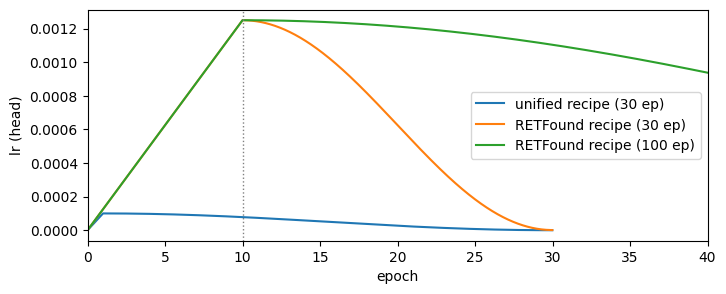

In [11]:
from src.model.baselines import LRSchedule, build_optimizer
def lr_curve(cfg_path, epochs, steps=70):
    c = load_config(cfg_path, [f"train.epochs={epochs}"])
    opt = build_optimizer(torch.nn.Linear(4, 1), {**c["optim"], "layer_decay": None}, 64)
    s = LRSchedule(opt, c["sched"], epochs, steps); out = []
    for e in range(1, epochs + 1):
        for _ in range(steps):
            s.before_step(); out.append(opt.param_groups[0]["lr"])
        s.end_epoch(e, 0.8)
    return np.arange(len(out)) / steps, np.array(out)
fig, ax = plt.subplots(figsize=(8, 3))
for path, ep, lab in [("config/unified/densenet121.yaml", 30, "unified recipe (30 ep)"),
                      ("config/pfm/retfound_mae_ft_flip30.yaml", 30, "RETFound recipe (30 ep)"),
                      ("config/pfm/retfound_mae_ft.yaml", 100, "RETFound recipe (100 ep)")]:
    e, lr = lr_curve(path, ep); ax.plot(e, lr, label=lab)
ax.axvline(10, color="gray", ls=":", lw=1); ax.set_xlabel("epoch"); ax.set_ylabel("lr (head)"); ax.set_xlim(0, 40); ax.legend(); plt.show()

## 4. Baseline training

`src/model/train_baseline.py` handles end-to-end training:
- every epoch is evaluated on val; the epoch with the best val AUC is saved as `best.pt` (full training state) with a readable
  `best.json`;
- `last.pt` supports resuming with `--resume`;
- at the end, predictions for val and test are written and evaluated into `metrics.json`;
- it refuses to overwrite an existing run of the same name.

The full set of experiments was queued over several GPUs with `scripts/dispatch.py`.

**Example 1**: the command for one training run. With `RUN_TRAINING_DEMO` on, it actually trains for 1 epoch on 256 images and writes
to a new run directory, leaving existing results untouched.

In [12]:
import subprocess
demo = f"notebook_demo_{time.strftime('%Y%m%d_%H%M%S')}"
cmd = [sys.executable, "-m", "src.model.train_baseline", "--config", "config/unified/densenet121.yaml",
       "--run-name", demo, "--limit", "256", "--set", "train.epochs=1", "eval.bootstrap=0"]
print("python", " ".join(cmd[1:]))
if RUN_TRAINING_DEMO:
    res = subprocess.run(cmd, capture_output=True, text=True, env={**os.environ, "PYTHONNOUSERSITE": "1"})
    print("\n".join(l for l in res.stdout.splitlines() if l.startswith(("epoch", "test:", "val:", "trainable"))))

python -m src.model.train_baseline --config config/unified/densenet121.yaml --run-name notebook_demo_20261125_220445 --limit 256 --set train.epochs=1 eval.bootstrap=0


**Example 2**: training curves from `log.csv` for the same DenseNet-121 under three recipes (seed 0).
- Paper learning rate (SGD 0.025): the training loss barely decreases and val AUC is unstable.
- Learning rate ×0.1 without augmentation: the training loss reaches nearly 0 within 5 epochs, i.e. the training set is memorized.
- Unified recipe (AdamW 1e-4 + augmentation): the training loss decreases steadily and val AUC is highest.

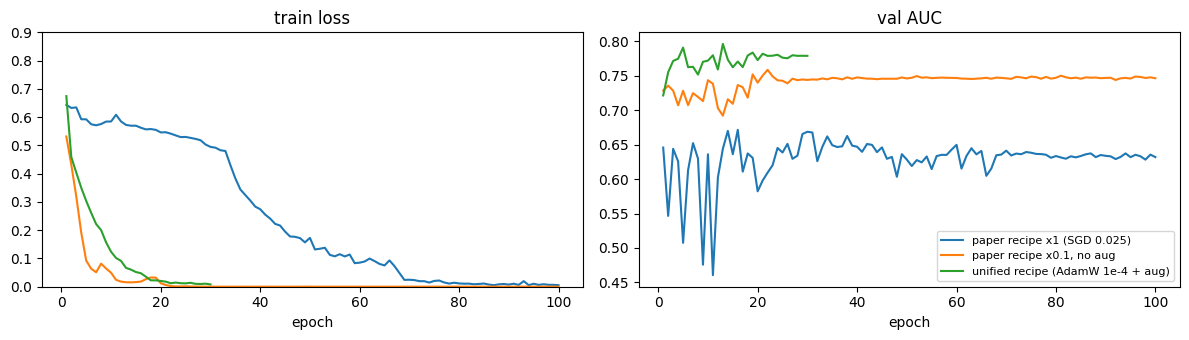

In [13]:
runs = {"paper recipe x1 (SGD 0.025)": "densenet121_none_s0", "paper recipe x0.1, no aug": "densenet121_none_lr0.1x_s0",
        "unified recipe (AdamW 1e-4 + aug)": "densenet121_ft_full_s0"}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for lab, r in runs.items():
    log = pd.read_csv(f"runs/{r}/log.csv")
    ax[0].plot(log.epoch, log.train_loss, label=lab); ax[1].plot(log.epoch, log.val_auc, label=lab)
ax[0].set_title("train loss"); ax[1].set_title("val AUC"); ax[0].set_xlabel("epoch"); ax[1].set_xlabel("epoch")
ax[0].set_ylim(0, 0.9); ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Example 3**: the files in one run directory, and what `best.json` records.

In [14]:
r = "runs/densenet121_ft_full_s0"
print(sorted(os.listdir(r)))
b = json.load(open(f"{r}/best.json"))
{k: b[k] for k in ("epoch", "val_auc", "val_loss", "train_loss", "lr_this_epoch", "model", "augment", "seed", "epochs_planned")}

['best.json', 'best.pt', 'config.yaml', 'features_test.npz', 'features_train.npz', 'features_val.npz', 'last.pt', 'log.csv', 'metrics.json', 'test_preds.csv', 'val_preds.csv']


{'epoch': 13,
 'val_auc': 0.7962929820793663,
 'val_loss': 0.6935378654381222,
 'train_loss': 0.06669437122249092,
 'lr_this_epoch': 6.345095953791745e-05,
 'model': 'densenet121.tv_in1k',
 'augment': 'full',
 'seed': 0,
 'epochs_planned': 30}

## 5. RETFound (retinal foundation model)

RETFound-MAE is a ViT-L/16 (303M parameters) pre-trained with MAE on about 0.9M fundus photographs; ODIR is not part of its
pretraining data. We compared several ways to adapt it:
- frozen encoder + linear head / MLP head;
- only the last 4 blocks trained;
- LoRA (r = 8, on qkv);
- LP-FT (linear head first, then full fine-tuning);
- full fine-tuning.

**Example 1**: adaptation strategies (test AUC, mean over 3 seeds), from the table written by `python -m src.api.summarize`.

In [15]:
pd.read_csv("results/adaptation.csv")[["arm", "val AUC", "test AUC", "test AUC sd", "AUC female", "AUC male"]].set_index("arm")

,val AUC,test AUC,test AUC sd,AUC female,AUC male
arm,,,,,
frozen + linear (RETFound recipe),0.770,0.768,5.502e-04,0.763,0.771
"frozen + linear (unified recipe, aug.)",0.718,0.720,6.684e-03,0.724,0.715
frozen + MLP 256,0.793,0.780,3.721e-03,0.774,0.786
frozen + MLP 512,0.790,0.777,6.408e-03,0.770,0.784
"LoRA r8 on qkv, lr 1e-3",0.796,0.797,7.943e-03,0.794,0.799
"LoRA r8 on qkv, lr 3e-4",0.793,0.800,2.250e-03,0.801,0.799
last 4 blocks,0.794,0.783,3.481e-03,0.770,0.794
LP-FT,0.789,0.788,9.615e-03,0.773,0.801
"full fine-tuning, 30 epochs",0.805,0.798,3.417e-03,0.791,0.805


**Example 2**: val AUC during full fine-tuning (RETFound official recipe, 100 epochs). The peak is always at epoch 9–10, the end of
warmup, when the learning rate is at its maximum. After that the model overfits and val AUC never recovers that level, which is
why methods that limit the parameter updates, such as LoRA, are worth trying.

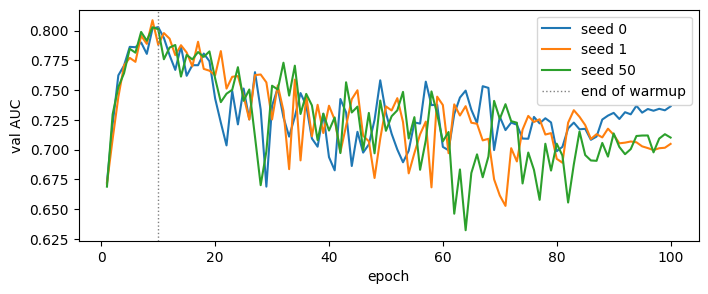

In [16]:
fig, ax = plt.subplots(figsize=(8, 3))
for s in SEEDS:
    log = pd.read_csv(f"runs/retfound_mae_ft_flip_s{s}/log.csv"); ax.plot(log.epoch, log.val_auc, label=f"seed {s}")
ax.axvline(10, color="gray", ls=":", lw=1, label="end of warmup"); ax.set_xlabel("epoch"); ax.set_ylabel("val AUC"); ax.legend(); plt.show()

**Example 3** (needs `LOAD_RETFOUND = True`): with LoRA wrapping the qkv layers, only 0.79M parameters train. Because the B matrices
start at zero, the model's output before training is exactly the original model's output.

In [17]:
if LOAD_RETFOUND:
    from src.model.baselines import build_model
    cache = "pretrained"
    torch.manual_seed(0); full, _ = build_model(load_config("config/pfm/retfound_mae_ft_flip30.yaml")["model"], cache)
    torch.manual_seed(0); lora, _ = build_model(load_config("config/pfm/retfound_mae_lora.yaml")["model"], cache)
    full.to(DEVICE).eval(); lora.to(DEVICE).eval()
    xr = torch.randn(2, 3, 224, 224, device=DEVICE)
    with torch.no_grad():
        print("max |full - LoRA| at init:", (full(xr) - lora(xr)).abs().max().item())
    print("trainable:", sum(p.numel() for p in lora.parameters() if p.requires_grad), "of", sum(p.numel() for p in lora.parameters()))
    del full, lora; torch.cuda.empty_cache()
else:
    print("LOAD_RETFOUND = False: skipped (loads 3.95 GB of weights)")

LOAD_RETFOUND = False: skipped (loads 3.95 GB of weights)


## 6. Cross-fitting

If a fusion head were trained on a backbone's features of its **own training images**, those features would already be memorized and
nearly separable, and whatever the head learns would not hold on test. Therefore:
- the training set is split into 5 patient-grouped, label-stratified folds (`splits/train_5fold.csv`); both eyes of a patient share a
  fold;
- for each fold, a backbone trained on the other 4 folds extracts features for that fold only (out-of-fold, OOF);
- val and test features come from a model with the same recipe trained on the whole training set.

**Example 1**: fold sizes and prevalence.

In [18]:
folds = pd.read_csv("splits/train_5fold.csv")
print("patients in more than one fold:", int((folds.groupby("patient")["fold"].nunique() > 1).sum()))
folds.groupby("fold").agg(images=("id", "size"), patients=("patient", "nunique"), prevalence=("label", "mean"))

patients in more than one fold: 0


,images,patients,prevalence
fold,,,
0,890,470,0.228
1,898,471,0.237
2,894,470,0.257
3,893,469,0.260
4,901,470,0.266


**Example 2**: each fold model's AUC on its held-out fold (seed 0). The values are close to the val AUC, so the OOF features
reflect real performance on unseen data.

In [19]:
rows = []
for b in ("retfound_mae_ft30", "densenet121_ft_full"):
    for k in range(5):
        o = pd.read_csv(f"runs/{b}_cv{k}_s0/oof_preds.csv")
        rows.append({"backbone": b, "fold": k, "OOF AUC": roc_auc_score(o.label, o.prob)})
pd.DataFrame(rows).pivot(index="fold", columns="backbone", values="OOF AUC")

backbone,densenet121_ft_full,retfound_mae_ft30
fold,,
0,0.777,0.800
1,0.789,0.774
2,0.783,0.798
3,0.760,0.793
4,0.799,0.802


## 7. Binocular and feature-level fusion (our method)

### 7.1 Probability-level binocular fusion (lightweight variant)

Average this eye's probability with the other eye's: $p' = (1-a)\,p_{\text{this eye}} + a\,p_{\text{other eye}}$. The weight $a$ is
chosen in 0–0.5 by val AUC; an image whose other eye is not in the same split keeps its own probability (`src/api/fuse.py`).

**Example**: DenseNet-121 (seed 0), computed in memory without writing files.

chosen a = 0.2 | test AUC single eye 0.7926 -> with other eye 0.8090


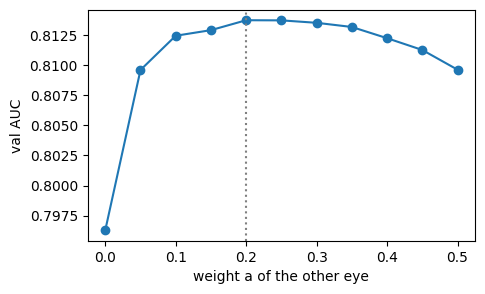

In [20]:
from src.api.fuse import load, fellow_prob
A = {sp: load("runs/densenet121_ft_full_s0", sp) for sp in ("val", "test")}
F = {sp: fellow_prob(A[sp]) for sp in A}
grid = np.round(np.arange(0, 0.51, 0.05), 2)
val_auc = [roc_auc_score(A["val"].label, (1 - w) * A["val"].prob + w * F["val"]) for w in grid]
w = grid[int(np.argmax(val_auc))]
fused = (1 - w) * A["test"].prob + w * F["test"]
print(f"chosen a = {w} | test AUC single eye {roc_auc_score(A['test'].label, A['test'].prob):.4f} -> with other eye {roc_auc_score(A['test'].label, fused):.4f}")
plt.figure(figsize=(5, 3)); plt.plot(grid, val_auc, marker="o"); plt.axvline(w, color="gray", ls=":")
plt.xlabel("weight a of the other eye"); plt.ylabel("val AUC"); plt.show()

### 7.2 Feature-level fusion (final method)

For each backbone $b \in$ {RETFound, DenseNet}, take this eye's feature $z$, the other eye's feature $z'$ and their difference
$|z - z'|$ (1024 dims each).
- Each block is standardized with training statistics and scaled by $1/\sqrt{1024}$, so that blocks contribute equally to
  regularization;
- one flag marks a missing other eye, giving 6 × 1024 + 1 = 6145 dims;
- all training features are cross-fitted (OOF), and the fusion head is an MLP (6145 → 256 → 1).

**Example 1**: build the fusion input (seed 0) and check dimensions and how often the other eye is missing.

In [21]:
from src.model import fusion_head as fh
blocks = [fh.load_backbone("runs", b, 0) for b in ("retfound_mae_ft30", "densenet121_ft_full")]
D = fh.design(blocks, eyes=True)
for sp, (X, df) in D.items():
    print(f"{sp:5s} X {X.shape} | other eye missing: {X[:, -1].mean():.1%} | DR prevalence {df.label.mean():.3f}")

train X (4476, 6145) | other eye missing: 5.0% | DR prevalence 0.250
val   X (641, 6145) | other eye missing: 4.5% | DR prevalence 0.285
test  X (1914, 6145) | other eye missing: 5.2% | DR prevalence 0.256


**Example 2**: train the MLP fusion head on these features (seed 0, about half a minute; epoch chosen by val AUC) and compare
with the DenseNet single model. The training AUC is clearly below 1, so cross-fitting prevented nearly separable, memorized
features.

In [22]:
prob, info = fh.fit_mlp(D, 0, DEVICE)
te = D["test"][1]
print(f"best epoch {info['best_epoch']} | train AUC {info['train_auc']:.3f} | val AUC {info['best_val_auc']:.4f}")
print(f"test AUC: fusion {roc_auc_score(te.label, prob['test']):.4f} vs DenseNet single eye "
      f"{roc_auc_score(A['test'].label, A['test'].prob):.4f}")

best epoch 8 | train AUC 0.911 | val AUC 0.8486
test AUC: fusion 0.8483 vs DenseNet single eye 0.7926


## 8. Results

### 8.1 Main table

`python -m src.api.summarize` collects every run (mean and SD over 3 seeds) into `results/`. Below are the main methods: baselines,
RETFound and our method.

In [23]:
cols = ["arm", "val AUC", "test AUC", "test AUC sd", "Sens", "Spec", "AUC female", "AUC male"]
main = pd.read_csv("results/main.csv")[cols]
fusion = pd.read_csv("results/fusion.csv")[cols]
final = fusion[fusion.arm.isin(["RETFound + DenseNet + eyes (prob.)", "RETFound30 + DenseNet + eyes features, MLP"])]
pd.concat([main, final]).set_index("arm")

,val AUC,test AUC,test AUC sd,Sens,Spec,AUC female,AUC male
arm,,,,,,,
"ResNet-50, unified recipe",0.796,0.775,9.448e-03,0.590,0.794,0.768,0.781
"DenseNet-121, unified recipe",0.802,0.793,2.043e-02,0.669,0.776,0.790,0.796
"ViT-B/16, unified recipe",0.772,0.767,5.987e-03,0.642,0.741,0.772,0.763
RETFound frozen + linear head,0.770,0.768,5.502e-04,0.662,0.740,0.763,0.771
RETFound frozen + MLP head,0.793,0.780,3.721e-03,0.683,0.723,0.774,0.786
"RETFound fine-tuned, own recipe + flip",0.805,0.798,3.417e-03,0.720,0.715,0.791,0.805
RETFound + DenseNet + eyes (prob.),0.842,0.836,9.833e-03,0.759,0.759,0.826,0.845
"RETFound30 + DenseNet + eyes features, MLP",0.844,0.841,6.925e-03,0.729,0.794,0.827,0.854


### 8.2 Ablation: fusion variants and same-size controls (RETFound + DenseNet vs DenseNet + DenseNet)

In [24]:
pd.read_csv("results/fusion.csv")[["arm", "val AUC", "test AUC", "test AUC sd"]].set_index("arm")

,val AUC,test AUC,test AUC sd
arm,,,
RETFound + DenseNet (prob.),0.829,0.819,0.012
RETFound 3-seed ensemble,0.816,0.809,NaN
DenseNet 3-seed ensemble,0.829,0.818,NaN
RETFound + eyes (prob.),0.814,0.812,0.005
DenseNet + eyes (prob.),0.819,0.810,0.016
ResNet + eyes (prob.),0.814,0.790,0.007
ViT-B + eyes (prob.),0.783,0.779,0.006
RETFound + DenseNet + eyes (prob.),0.842,0.836,0.010
RETFound ens. + eyes (prob.),0.826,0.824,NaN


### 8.3 Paired tests

`paired_bootstrap(A, B)` returns the test AUC difference A − B (averaged over 3 seeds), its 95% CI and a p-value, resampling patients.
**Example**: final method vs DenseNet-121 with `N_BOOT` resamples; all reported tests use 2,000 resamples and are in
`results/comparisons.csv`.

In [25]:
from src.api.stats import paired_bootstrap
d, lo, hi, pv = paired_bootstrap("fusion/rf30+dn_eyes_mlp", "densenet121_ft_full", n_boot=N_BOOT)
print(f"final - DenseNet: {d:+.4f}  95% CI [{lo:+.4f}, {hi:+.4f}]  p = {pv:.4f}")
pd.read_csv("results/comparisons.csv").round(4)

final - DenseNet: +0.0476  95% CI [+0.0349, +0.0623]  p = 0.0050


,A,B,diff,ci_low,ci_high,p
0,retfound_mae_ft_flip,densenet121_ft_full,0.005,-1.470e-02,0.025,6.090e-01
1,retfound_mae_ft_flip,vit_b16_ft_full,0.032,1.340e-02,0.049,5.000e-04
2,fusion/rf+dn,fusion/dn_seedens,0.001,-1.050e-02,0.013,8.730e-01
3,fusion/rf+eyes,retfound_mae_ft_flip,0.013,7.400e-03,0.020,5.000e-04
4,fusion/dn+eyes,densenet121_ft_full,0.017,9.700e-03,0.024,5.000e-04
5,fusion/rf+dn+eyes,densenet121_ft_full,0.042,2.950e-02,0.056,5.000e-04
6,fusion/rf+dn+eyes,fusion/dn_seedens+eyes,0.004,-7.500e-03,0.015,5.860e-01
7,fusion/rf30+dn_feat,fusion/rf30+dn,0.005,-5.000e-04,0.010,7.100e-02
8,fusion/rf30+dn_eyes_feat,fusion/rf30+dn+eyes,0.003,-4.200e-03,0.010,4.470e-01
9,fusion/rf30+dn_eyes_feat,densenet121_ft_full,0.045,2.990e-02,0.060,5.000e-04


### 8.4 ROC curves (probabilities averaged over 3 seeds)

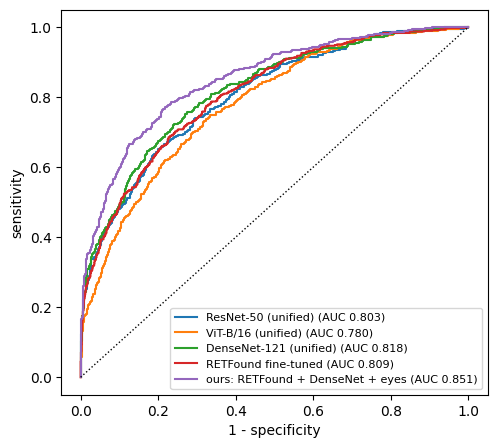

In [26]:
def avg_probs(prefix):
    dfs = [pd.read_csv(f"runs/{prefix}_s{s}/test_preds.csv").set_index("id").sort_index() for s in SEEDS]
    return dfs[0].label.to_numpy(), np.mean([d.prob.to_numpy() for d in dfs], axis=0)
plt.figure(figsize=(5.5, 5))
for lab, pre in [("ResNet-50 (unified)", "resnet50_ft_full"), ("ViT-B/16 (unified)", "vit_b16_ft_full"),
                 ("DenseNet-121 (unified)", "densenet121_ft_full"), ("RETFound fine-tuned", "retfound_mae_ft_flip"),
                 ("ours: RETFound + DenseNet + eyes", "fusion/rf30+dn_eyes_mlp")]:
    yy, pp = avg_probs(pre); fpr, tpr, _ = roc_curve(yy, pp)
    plt.plot(fpr, tpr, label=f"{lab} (AUC {roc_auc_score(yy, pp):.3f})")
plt.plot([0, 1], [0, 1], "k:", lw=1); plt.xlabel("1 - specificity"); plt.ylabel("sensitivity"); plt.legend(fontsize=8); plt.show()

### 8.5 Patient-level DR and sex groups

- **Patient level**: a patient is positive if either eye has DR, and the patient score is the maximum of the two eyes' probabilities.
  This matches how ODIR labels patients, but it is not ODIR's standard 8-class evaluation.
- **Sex**: the assignment asks for female AUC and male AUC separately.

In [27]:
rows = []
for lab, pre in [("DenseNet-121", "densenet121_ft_full"), ("RETFound fine-tuned", "retfound_mae_ft_flip"), ("ours", "fusion/rf30+dn_eyes_mlp")]:
    pat, fem, mal = [], [], []
    for s in SEEDS:
        t = pd.read_csv(f"runs/{pre}_s{s}/test_preds.csv"); t["pid"] = t.id.str.rsplit("_", n=1).str[0]
        g = t.groupby("pid").agg(y=("label", "max"), p=("prob", "max"))
        pat.append(roc_auc_score(g.y, g.p))
        fem.append(roc_auc_score(t.label[t.male == 0], t.prob[t.male == 0])); mal.append(roc_auc_score(t.label[t.male == 1], t.prob[t.male == 1]))
    rows.append({"method": lab, "patient-level AUC": np.mean(pat), "female AUC": np.mean(fem), "male AUC": np.mean(mal),
                 "female - male": np.mean(fem) - np.mean(mal)})
pd.DataFrame(rows).set_index("method")

,patient-level AUC,female AUC,male AUC,female - male
method,,,,
DenseNet-121,0.792,0.790,0.796,-0.006
RETFound fine-tuned,0.804,0.791,0.805,-0.015
ours,0.824,0.827,0.854,-0.027


## 9. Summary

- Under one training and evaluation protocol, DenseNet-121 is the strongest single baseline (0.793); fine-tuned RETFound reaches 0.798,
  not significantly different.
- **The other eye** gives every backbone a significant +0.012 to +0.017; **multi-model feature fusion** adds about +0.02 more.
- The final method reaches a test AUC of **0.841**, +0.048 over DenseNet-121 (p < 0.001), with higher sensitivity, specificity, and
  female and male AUC at the same time.
- With the same number of models, RETFound has only a consistent small advantage over a second DenseNet (+0.008 to +0.012).
- Details are in `docs/method_and_results.md` and future work in `docs/future_work.md`.